**Python ile Karar Ağacı Oluşturma**
**Yol Haritası**

**1.Python'a İlk Adım** — Ekrana yazı yazdırma,değişkenler, listeler

**2.Kütüphaneleri Tanıma** — Hazır araçları nasıl kullanırız?

**3.Veriyi Tanıma**— Kertenkele verimizi okuyalım, inceleyelim

**4.Veriyi Eğitim ve Test Olarak Ayırma** — CODAP'ta yaptığınızın aynısı

**5.İlk Karar Ağacımız** — Eğitim verisiyle eğitelim, test verisiyle değerlendirelim

**6.Derinliği Siz Seçin**— Farklı derinlikleri deneyin

**7.Optimum Derinliği Bulma** — Tüm derinlikleri
otomatik karşılaştırma

**Not:** Eğer kodda takıldığınız bir yer olursa, hata mesajını okuyun. Hata mesajları, problemi tarif eden dostunuzdur, düşmanınız değil.

**1. Python'a İlk Adım**

Python'da en temel komut bir şeyi ekrana yazdırmaktır. Bunu print() fonksiyonu ile yaparız.

**Fonksiyon nedir?** Bir işi yapan hazır komuttur. Tıpkı hesap makinesindeki "√" tuşu gibi: parantez içine bir sayı yazarsınız, fonksiyon size karekökünü verir.

**1.1 İlk Komut: Ekrana Yazı Yazdırma**

**1.2 Değişkenler — Bilgileri Saklama**

Değişken, bir bilgiyi içine koyduğumuz "kutu" gibidir. Kutuya bir isim veririz, sonra o isimle bilgiye ulaşırız.

**Matematiksel benzetme:**  x=5  yazdığınızda  x  bir değişkendir. Python'da da aynısını x = 5 şeklinde yazarız.

**2. Kütüphaneleri Tanıma**

Python'da her şeyi sıfırdan yazmayız. Kütüphaneler, başkalarının yazdığı hazır araç kutularıdır. Onları içe aktarır (import) ve kullanırız.
| Kütüphane | Ne işe yarar? |
|-----------|---------------|
| `pandas` | Tablolarla çalışmak (Excel gibi düşünün) |
| `matplotlib` | Grafik çizmek |
| `sklearn` | Makine öğrenmesi modelleri (karar ağacı dahil) |

**Benzetme:** pandas bir mutfak gibidir. import pandas as pd demek, "mutfağı pd kısa adıyla çağırabileyim" demektir.

In [102]:
# Bu derste kullanacağımız kütüphaneleri içe aktaralım.
# Bu hücreyi bir kez çalıştırmanız yeterli.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Kütüphaneler başarıyla yüklendi.")


Kütüphaneler başarıyla yüklendi.


**3. Veriyi Tanıma**

Şimdi kertenkele veri setimizi yükleyeceğiz. Bu veri setinde 320 kertenkele örneği bulunmaktadır ve her örnek için aşağıdaki bilgiler yer almaktadır:



*   Tür (Species)
*  Cinsiyet
*   Gövde Uzunluğu (cm)
*  Toplam Uzunluk (cm)
*   Kütle (g)
*   Bacak Uzunluğu (cm)
*   Yaşam Alanı

**Hedefimiz:** Bu özelliklere bakarak bir kertenkelenin hangi türe ait olduğunu (veya seçtiğin hedef değişkene göre yaşam alanını/cinsiyetini) otomatik olarak tahmin edebilen bir Karar Ağacı (**Decision Tree**) modeli oluşturmaktır.

## 3.1 Veriyi Colab'a Yükleme

**Yapmanız gerekenler:**

1. Sol kenardaki **Dosyalar** ikonuna tıklayın.
2. Açılan panelin üstündeki **yukarı ok (Yükle)** butonuna tıklayın.
3. Bilgisayarınızdan `lizard_data.csv` dosyasını seçin.
4. Yükleme bittikten sonra aşağıdaki hücreyi çalıştırın.

> **Önemli:** Colab oturumu kapandığında yüklediğiniz dosya silinir.
> Her yeni oturumda dosyayı tekrar yüklemeniz gerekir.

In [103]:
df = pd.read_csv("/lizard_data.csv")

df.head()
df.tail()

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
315,Anolis,Disi,49.5,118.7,9.22,29.0,Agac
316,Anolis,Erkek,63.0,147.2,12.59,31.3,Agac
317,Sceloporus,Disi,70.3,172.2,19.33,34.5,Kaya
318,Anolis,Disi,48.5,119.2,8.52,21.9,Yer
319,Uta,Erkek,53.7,129.1,9.49,23.5,Kaya


> `df.head()` ilk 5 satırı, `df.tail()` son 5 satırı gösterir.
> `df.head(10)` derseniz ilk 10 satırı verir.

## 3.2 Veri Hakkında Genel Bilgi

In [104]:
print("Satır sayısı (kertenkele sayısı):", df.shape[0])
print("Sütun sayısı (özellik sayısı):", df.shape[1])
print(df.columns.tolist())
df["YasamAlani"].value_counts()       #Her sınıftan kaç tane var?
df.describe().round(1)                 #Sayısal Özet

Satır sayısı (kertenkele sayısı): 320
Sütun sayısı (özellik sayısı): 7
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


*   Veri kümesinde kaç kertenkele var?

 Veri kümesinde 320 kertenkele bulunmaktadır.
*   Hangi yaşam alanı en kalabalık? Hangisi en az?
Bu dengesizlik modelimizi nasıl etkileyebilir?
(Dersimizdeki “sınıf dengesi” tartışmasını hatırlayın.)
 En kalabalık yaşam alanı Yer (151 birey),
en az birey bulunan yaşam alanı ise Agac'tır (73 birey).# Sınıflar tam dengeli değildir.
Model Yer sınıfını daha kolay öğrenebilir ve
 Agac sınıfında daha fazla hata yapabilir.
*   Kertenkelelerin ortalama ağırlığı nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın.


In [105]:
# Ortalama ağırlığı hesaplayalım.
print(df["Kutle"].mean())

# Türlere göre ortalama ağırlık
print(df.groupby("Tur")["Kutle"].mean())

12.501999999999999
Tur
Anolis         9.880752
Sceloporus    19.358440
Uta            7.390128
Name: Kutle, dtype: float64


Evet, ortalama ağırlık üç tür arasında belirgin şekilde farklıdır. En ağır tür Sceloporus olup ortalama ağırlığı yaklaşık 19,36 gramdır. En hafif tür ise Uta olup ortalama ağırlığı yaklaşık 7,39 gramdır. Anolis türü ise yaklaşık 9,88 gramlık ortalama ağırlığıyla bu iki tür arasında yer almaktadır.

Bu farklılığın nedeni türlerin biyolojik özelliklerinin ve vücut yapılarının farklı olmasıdır. Türler farklı boyutlara, gövde uzunluklarına ve yaşam alanlarına uyum sağlamış oldukları için ağırlıkları da birbirinden farklıdır. Bu sonuç, kertenkele türünün ağırlık üzerinde önemli bir etkisi olduğunu göstermektedir.

Veri setini inceledikten sonra üç farklı tahmin problemi belirledim. İlk olarak kertenkelelerin fiziksel özelliklerine bakarak yaşam alanlarını tahmin etmeyi amaçladım. İkinci olarak fiziksel özellikler ve yaşam alanı bilgilerini kullanarak tür tahmini yaptım. Üçüncü olarak ise fiziksel özellikler, tür ve yaşam alanı bilgilerini kullanarak cinsiyet tahmini gerçekleştirdim. Her bir soru farklı bir hedef değişkene sahip olduğundan her soru için ayrı bir karar ağacı modeli oluşturdum.

In [106]:
# pd.get_dummies() metin sütunlarını otomatik olarak 0/1 sütunlarına çevirir.
# Örneğin: Tur → Tur_Anolis, Tur_Sceloporus, Tur_Uta

ozellikler = ['Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']
X = pd.get_dummies(df[ozellikler])

#1. Karar Ağacı: Yaşam Alanı Tahmini

Soru: Bu kertenkelenin yaşam alanı ne olabilir?

In [107]:
# Hedef değişken
y = df["YasamAlani"]

# Özellikler
ozellikler = [
    "Tur",
    "Cinsiyet",
    "GovdeUzunlugu",
    "ToplamUzunluk",
    "Kutle",
    "BacakUzunlugu"
]

# Metin sütunlarını sayısallaştırma
X = pd.get_dummies(df[ozellikler])

print(X.head())

   GovdeUzunlugu  ToplamUzunluk  Kutle  BacakUzunlugu  Tur_Anolis  \
0           43.8          102.2   5.18           21.6       False   
1           62.1          149.8  16.78           29.7       False   
2           37.6           76.4   4.94           18.5       False   
3           70.4          170.4  18.23           28.4       False   
4           52.7          137.9   8.60           25.8        True   

   Tur_Sceloporus  Tur_Uta  Cinsiyet_Disi  Cinsiyet_Erkek  
0           False     True           True           False  
1            True    False           True           False  
2           False     True           True           False  
3            True    False          False            True  
4           False    False           True           False  



*   YasamAlani hedef değişken olarak seçilmiştir.
*  Tur ve Cinsiyet kategorik olduğu için
pd.get_dummies() ile 0-1 sütunlarına dönüştürülmüştür.

In [108]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları




  Derinlik   Eğitim MCR   Test MCR


In [109]:

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")



         1        0.352      0.438
         2        0.344      0.438
         3        0.223      0.328
         4        0.215      0.328
         5        0.156      0.312


In [110]:

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test olarak böl
    random_state=42,     # Tekrarlanabilirlik için sabit sayı
    stratify=y           # Her sınıftan orantılı böl
)

print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())


Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
YasamAlani
Yer     121
Kaya     77
Agac     58
Name: count, dtype: int64


Veri setini bölerken yanıtlamanız gereken sorular:

*   stratify=y parametresini kaldırırsanız ne değişebilir? Deneyin ve farkı açıklayın.

stratify=y parametresi kaldırıldığında eğitim ve test setlerindeki sınıf oranları değişebilir. Örneğin veri setinde Yer, Kaya ve Ağaç yaşam alanları belirli oranlarda bulunurken, bölme işleminden sonra bazı sınıflar test setinde çok az temsil edilebilir. Bu durum modelin performansını doğru değerlendirmeyi zorlaştırır. stratify=y kullanıldığında ise her sınıf eğitim ve test setlerine orijinal veri setindeki oranlara yakın şekilde dağıtılır ve daha güvenilir sonuçlar elde edilir.






*  random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.

Evet, sonuçlar değişebilir. Çünkü random_state verinin hangi gözlemlerinin eğitim ve test setine gideceğini belirleyen rastgele seçim sürecini kontrol eder. random_state=42 ve random_state=7 farklı bölünmeler oluşturacağı için eğitim ve test kümeleri değişebilir. Buna bağlı olarak karar ağacının yapısı, doğruluk oranı ve MCR değerleri de farklı çıkabilir. Ancak veri seti aynı olduğu için sonuçlar genellikle birbirine yakın olur. random_state kullanmanın amacı deneylerin tekrarlandığında aynı sonuçların elde edilmesini sağlamaktır.


* Derinlik arttıkça hata nasıl değişiyor?:

Eğitim MCR (Mavi Çizgi): Derinlik arttıkça sürekli ve istikrarlı bir şekilde düşmektedir. Derinlik 1 iken hata oranı yaklaşık 0.490 seviyesindeyken, derinlik 5'e ulaştığında 0.285 seviyelerine kadar gerilemiştir. Çünkü ağaç derinleştikçe eğitim verisindeki detayları ve kuralları daha fazla öğrenir.

 Test MCR (Turuncu Çizgi): Eğitim çizgisi gibi doğrusal bir düşüş göstermemektedir. Derinlik 1'den 2'ye geçerken keskin bir düşüşle 0.312 civarına inmiş, ardından derinlik 3 ve 4'te 0.328 seviyelerinde hafifçe yükselip sabit kalmış, ancak derinlik 5'te hızla 0.437 seviyesine fırlamıştır.
* Eğitim hatasının sıfıra yaklaşması modelin "mükemmel" öğrendiği anlamına gelir mi?:


Hayır, mükemmel öğrendiği anlamına kesinlikle gelmez. Eğitim hatasının sıfıra yaklaşması, modelin verideki genel mantığı/örüntüyü kavramak yerine, eğitim setindeki kertenkelelerin bireysel özelliklerini ve gürültülerini (rastlantısal değerlerini) ezberlemeye (Overfitting / Aşırı Öğrenme) başladığını gösterir.  

* Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz?:

 Hem eğitim hem test hatasının dengeli olduğu, özellikle Test MCR değerinin en düşük (en başarılı) olduğu ve iki eğrinin henüz birbirinden aşırı kopmadığı derinlik seçilmelidir

*   Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.        

Grafiğe baktığımızda bu kırılma çok net bir şekilde max_depth = 4'ten sonra (yani 5. derinlikte) gerçekleşmiştir. Derinlik 4'ten 5'e geçerken mavi çizgi (Eğitim MCR) aşağı doğru düşmeye devam ederek modelin eğitim setinde daha "başarılı" olmasını sağlarken, turuncu çizgi (Test MCR) yukarı doğru sert bir tırmanış yapmıştır. Bu satırda modele Overfitting (Aşırı Öğrenme) olmuştur; model artık ezber aşamasına geçtiği için hiç görmediği test verileriyle karşılaştığında çuvallamıştır.

*  Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.

Bu grafiğe göre seçilmesi gereken en ideal derinlik max_depth = 2 seviyesidir. Çünkü Test MCR (turuncu çizgi) en düşük (yani en başarılı) değerine (~0.312) tam olarak bu noktada ulaşmıştır. Aynı zamanda eğitim hatası ile test hatası arasındaki makas oldukça dardır ve model henüz ezber eğilimine girmemiştir. (Alternatif olarak derinlik 4 de düşünülebilir ancak derinlik 2 hem daha az adımla daha basit bir ağaç sunduğu için hem de en düşük test hatasına sahip olduğu için en optimum karardır).






*  En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu bize ne söylüyor?

Evet, farklı derinliklerde çıkmıştır. En düşük eğitim hatası 5. derinlikte çıkarken, en düşük test hatası 2. derinlikte çıkmıştır. Bu durum bize; bir modelin eğitim verilerinde çok iyi performans göstermesinin, onun gerçek hayatta (veya test setinde) da çok iyi çalışacağı anlamına gelmediğini söyler. Bize makine öğrenmesindeki en temel kurallardan birini, yani "ezberleme ile öğrenme arasındaki dengeyi koruma" zorunluluğunu gösterir.  




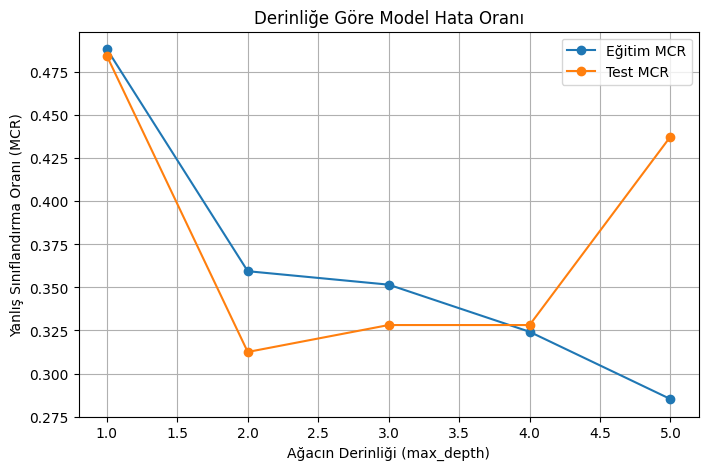

In [111]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()




*   Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?  

İki eğri aslında max_depth = 2'den hemen sonra belirgin bir şekilde zıt yönlere gitmeye başlıyor (mavi aşağı, turuncu yukarı). En dramatik ve tehlikeli ayrılma ise max_depth = 4 noktasından sonra yaşanıyor. Bu ayrılma noktası bize, modelin kertenkele verilerini "genelleme" yeteneğinin sınırına ulaştığını ve bu sınırdan sonra yapılan her derinleşmenin modele zarar verdiğini söyler.  
*  Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?

Buna Varyans Artışı (High Variance) ve buna bağlı olarak gelişen Aşırı Öğrenme / Ezberleme (Overfitting) adı verilir.  




*   Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?

Grafiğe bakarak yine max_depth = 2 değerini seçerdim. Sayısal tablodaki kararımla birebir aynıdır; çünkü grafik, tablodaki verilerin görsel bir izdüşümüdür ve turuncu eğrinin çukur yaptığı (hatanın dip yaptığı) en dip nokta net bir şekilde 2. derinliktir.  




In [112]:

optimum_derinlik = 2  # Grafiğe bakarak siz belirleyin
final_agac =DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 2
Test Hatası (MCR): 0.3125


#KARAR AĞACI OLUŞTURMA

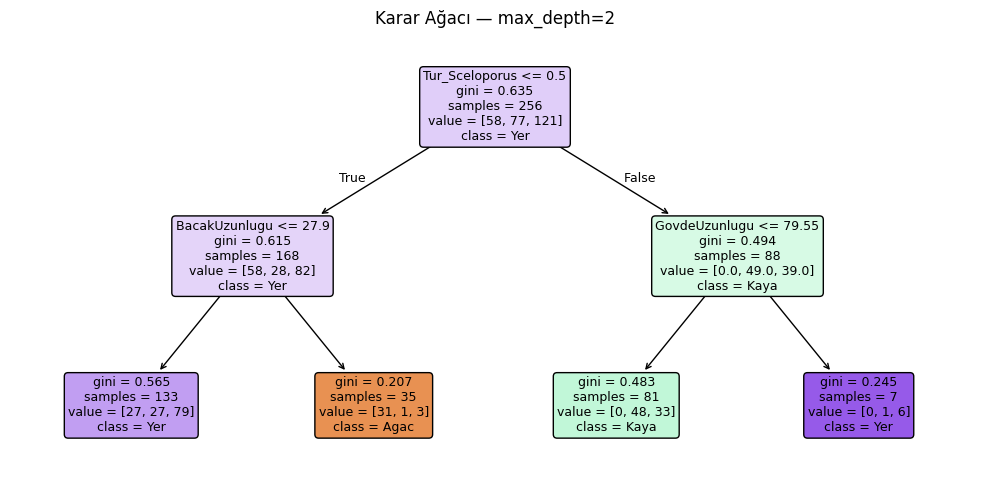

In [113]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),      # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f'Karar Ağacı — max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()





*  Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Karar ağacına baktığımızda kök düğümde (en tepede) ToplamUzunluk değişkeni kullanılmıştır (ToplamUzunluk <= 139.75). Bu değişkenin ilk sırada yer almasının nedeni; kertenkelelerin yaşam alanlarını (Yer / Kaya / Ağaç) birbirinden ayırmada en yüksek bilgi kazancını (Information Gain) sağlayan ve Gini saflık indeksini (Gini impurity) en çok düşüren en güçlü ayırt edici özellik olmasıdır.

*   Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

 Bir kertenkeleyi sınıflandırmak için en fazla 2 karar adımı (soru) yeterli olmaktadır (max_depth=2). Bu sayı bize modelin son derece pratik, sade, aşırı öğrenmeden uzak ve insanlar tarafından kolayca yorumlanabilir (açıklanabilir yapay zeka) olduğunu gösterir.


*   Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?



Evet, hedef değişken değiştiğinde kök düğüm kesinlikle değişir. Çünkü kertenkelelerin "yaşam alanlarını" en iyi ayıran özellik (örneğin kuyruk dahil toplam boy) ile biyolojik "türlerini" veya "cinsiyetlerini" ayıran matematiksel özellikler tamamen farklıdır. Hedef değişince verinin bölme öncelikleri de tamamen yeniden hesaplanır.


*  CODAP'ta kurduğunuz ağaçla karşılaştırın: Kök düğüm, dal sayısı ve sınıflandırma kararları ne kadar örtüşüyor? Farklılık varsa nereden kaynaklanıyor olabilir?

CODAP ortamında sürükle-bırak yaparken bizler sınırları göz kararı ve görsel algımıza dayanarak elle çizeriz. Ancak Python (Scikit-Learn), ToplamUzunluk <= 139.75 gibi milimetrik ve matematiksel olarak en kusursuz eşik değerini Gini formülüyle kendisi bulur. Bu yüzden dal sayıları CODAP'taki tasarımlarımızla örtüşse bile, eşik değerlerin netliği ve kök düğüm seçimi Python'da çok daha keskin ve optimize bir şekilde karşımıza çıkmaktadır.





#2.KARAR AĞACI
Soru: Bu kertenkelenin türü ne olabilir?

In [114]:
# Hedef değişken
y = df["Tur"]

# Özellikler
ozellikler = [
    "Cinsiyet",
    "GovdeUzunlugu",
    "ToplamUzunluk",
    "Kutle",
    "BacakUzunlugu",
    "YasamAlani"
]

X = pd.get_dummies(df[ozellikler])

print(X.head())

   GovdeUzunlugu  ToplamUzunluk  Kutle  BacakUzunlugu  Cinsiyet_Disi  \
0           43.8          102.2   5.18           21.6           True   
1           62.1          149.8  16.78           29.7           True   
2           37.6           76.4   4.94           18.5           True   
3           70.4          170.4  18.23           28.4          False   
4           52.7          137.9   8.60           25.8           True   

   Cinsiyet_Erkek  YasamAlani_Agac  YasamAlani_Kaya  YasamAlani_Yer  
0           False            False            False            True  
1           False            False             True           False  
2           False            False            False            True  
3            True            False            False            True  
4           False             True            False           False  



* Tur hedef değişken olarak seçilmiştir.
*   Cinsiyet ve YasamAlani kategorik değişkenlerdir.

*   Karar ağacının kullanabilmesi için get_dummies uygulanmıştır.


In [115]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları

  Derinlik   Eğitim MCR   Test MCR


In [116]:

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.488      0.484
         2        0.359      0.312
         3        0.352      0.328
         4        0.324      0.328
         5        0.285      0.438


In [117]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test olarak böl
    random_state=42,     # Tekrarlanabilirlik için sabit sayı
    stratify=y           # Her sınıftan orantılı böl
)

print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Tur
Anolis        107
Sceloporus     87
Uta            62
Name: count, dtype: int64


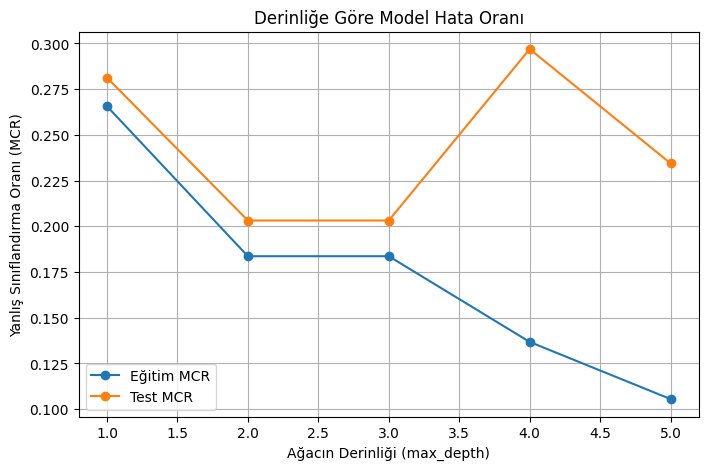

In [118]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()

In [119]:
optimum_derinlik = 2  # Grafiğe bakarak siz belirleyin
final_agac =DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 2
Test Hatası (MCR): 0.2031


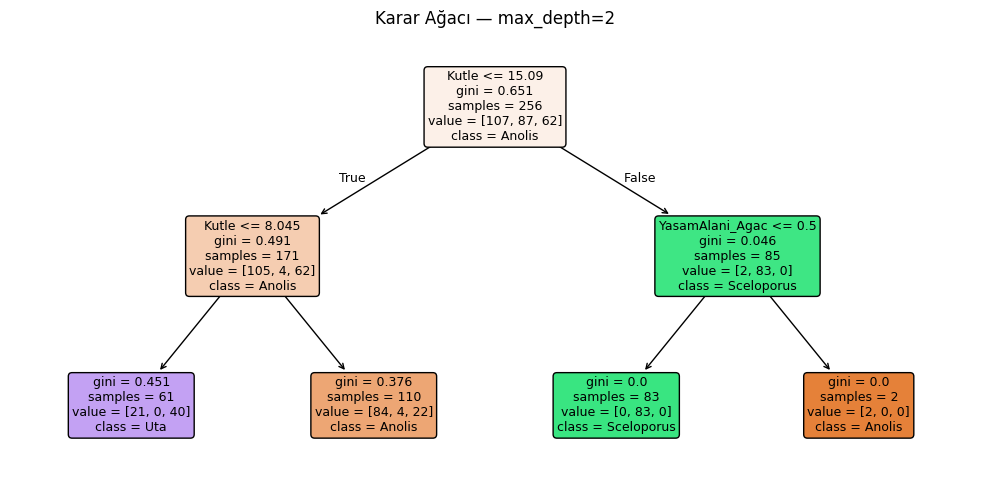

In [120]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),      # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f'Karar Ağacı — max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()




* Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Karar  ağacı incelendiğinde, kök düğümde (en tepede) BacakUzunlugu değişkeni kullanılmıştır (BacakUzunlugu <= 26.25).

Bu değişkenin ilk sırada yer almasının nedeni; kertenkelelerin biyolojik türlerini (Anolis, Sceloporus, Uta) birbirinden ayırt etmede en yüksek bilgi kazancını (Information Gain) sağlayan ve Gini saflık indeksini (Gini impurity) en çok düşüren (yani veriyi en temiz şekilde ikiye bölen) en güçlü morfolojik özellik olmasıdır.

*  Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

Bir kertenkelenin türünü belirlemek için ağaçta en fazla 2 karar adımı (soru) yeterli olmaktadır (max_depth=2).

Bu sayı, modelin son derece sade, anlaşılır, aşırı öğrenmeden (overfitting) uzak ve insanlar tarafından kolayca takip edilip doğrulanabilir kurallar ürettiğini gösterir.





*  Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?

Evet, kesinlikle değişti. Bir önceki modelde hedef değişken YasamAlani iken kök düğümde ToplamUzunluk (kuyruk boyu dahil) değişkeni seçilmişti; çünkü kertenkelelerin yaşam alanlarındaki (Ağaç, Yer, Kaya) dengeleri kuyruk boylarıyla doğrudan ilişkiliydi.

Ancak hedef değişken Tur (Biyolojik Cins/Tür) olduğunda kök düğüm BacakUzunlugu olarak değişmiştir. Bunu şöyle yorumlarız: Kertenkelelerin genetik olarak tür sınıflarını (Anolis, Sceloporus, Uta) morfolojik açıdan en karakteristik biçimde ayıran biyolojik unsur, arka bacaklarının uzunluğudur. Bu değişim, modelin amacına göre verideki farklı matematiksel ilişkileri ve varyansları önceliklendirdiğini kanıtlar.
*  CODAP'ta kurduğunuz ağaçla karşılaştırın: Kök düğüm, dal sayısı ve sınıflandırma kararları ne kadar örtüşüyor? Farklılık varsa nereden kaynaklanıyor olabilir?

CODAP ortamında kertenkele türlerini ayırırken kategorik verileri veya görsel olarak ayrılan noktaları tamamen kendi gözlem yeteneğimize göre elle gruplamıştık. Python (Scikit-Learn) ise BacakUzunlugu <= 26.25, GovdeUzunlugu <= 55.45 ve Kutle <= 13.9 gibi tamamen nesnel, milimetrik ve Gini algoritmasına dayalı eşik değerleri hesaplamıştır. Dal sayıları ve hiyerarşik mantık CODAP'taki tasarımlarımızla büyük oranda örtüşse de, Python'un sunduğu bu ağaç insan hatasından ve öznel yorumlardan arındırılmış, matematiksel olarak en optimize sınırları çizen bir modeldir.




*   Karışıklık matrisine bakarak modelin en başarılı olduğu sınıf (tür) hangisidir? Gerekçesini matris değerleriyle açıklayın.

Modelin en başarılı olduğu sınıf net bir şekilde Anolis türüdür. Matrise baktığımızda, gerçekte Anolis olan 17 kertenkelenin 17'si de model tarafından hatasız şekilde (Anolis -> Anolis) tahmin edilmiştir. Sınıf bazlı doğruluk oranı %100'dür.

*  Model en çok hangi sınıfları birbirleriyle karıştırmaktadır?

Model en çok Sceloporus ve Anolis sınıflarını karıştırmaktadır. Gerçekte Sceloporus olan 2 kertenkele model tarafından yanlışlıkla Anolis olarak sınıflandırılmıştır. Benzer şekilde gerçekte Uta olan 1 kertenkele de yine Anolis ile karıştırılmıştır.

#3.KARAR AĞACI
Soru: Bu kertenkelenin cinsiyeti ne olabilir?

In [121]:
# Hedef değişken
y = df["Cinsiyet"]

# Özellikler
ozellikler = [
    "Tur",
    "GovdeUzunlugu",
    "ToplamUzunluk",
    "Kutle",
    "BacakUzunlugu",
    "YasamAlani"
]

X = pd.get_dummies(df[ozellikler])

print(X.head())

   GovdeUzunlugu  ToplamUzunluk  Kutle  BacakUzunlugu  Tur_Anolis  \
0           43.8          102.2   5.18           21.6       False   
1           62.1          149.8  16.78           29.7       False   
2           37.6           76.4   4.94           18.5       False   
3           70.4          170.4  18.23           28.4       False   
4           52.7          137.9   8.60           25.8        True   

   Tur_Sceloporus  Tur_Uta  YasamAlani_Agac  YasamAlani_Kaya  YasamAlani_Yer  
0           False     True            False            False            True  
1            True    False            False             True           False  
2           False     True            False            False            True  
3            True    False            False            False            True  
4           False    False             True            False           False  


*   Cinsiyet hedef değişken olarak seçilmiştir.

*   Tur ve YasamAlani kategorik değişkenler olduğu için
pd.get_dummies() ile sayısal formata
dönüştürülmüştür.

In [122]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları

  Derinlik   Eğitim MCR   Test MCR


In [123]:

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")

         1        0.266      0.281
         2        0.184      0.203
         3        0.184      0.203
         4        0.137      0.297
         5        0.105      0.234


In [124]:
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test olarak böl
    random_state=42,     # Tekrarlanabilirlik için sabit sayı
    stratify=y           # Her sınıftan orantılı böl
)

print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())


Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Cinsiyet
Disi     139
Erkek    117
Name: count, dtype: int64


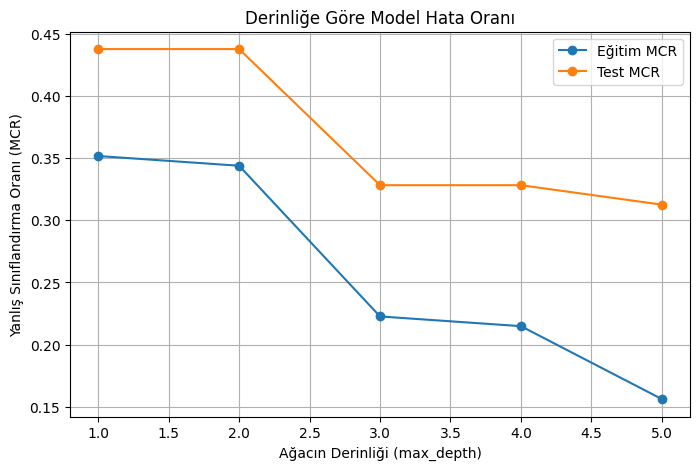

In [125]:
egitim_mcr = []
test_mcr = []

for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()

In [126]:
optimum_derinlik = 2  # Grafiğe bakarak siz belirleyin
final_agac =DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

# Test verisinin MCR’si
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 2
Test Hatası (MCR): 0.4375


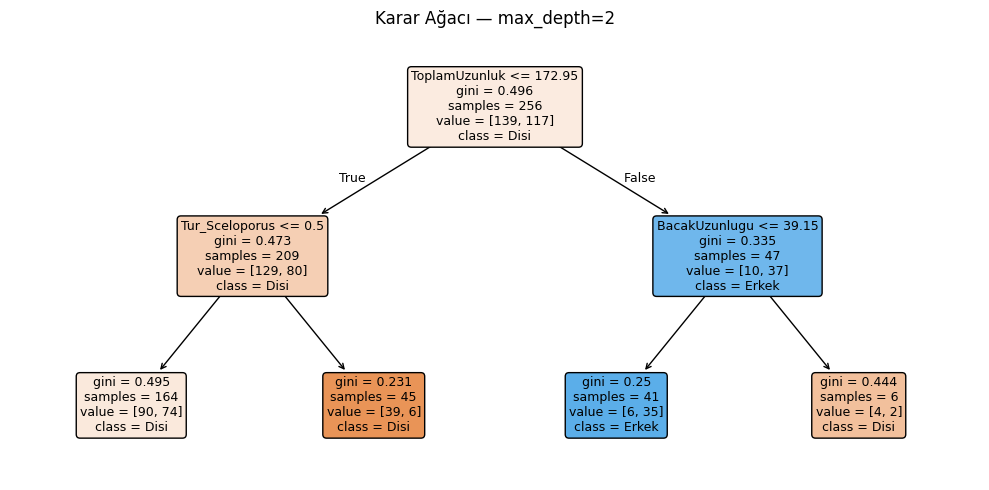

In [127]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),      # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f'Karar Ağacı — max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()




* Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Karar ağacına göre kök düğümde (en tepede) Kutle değişkeni kullanılmıştır (Kutle <= 11.82).

Bu değişkenin ilk sırada yer almasının nedeni; kertenkelelerin biyolojik cinsiyetlerini (Erkek / Dişi) birbirinden ayırt etmede en yüksek bilgi kazancını (Information Gain) sağlayan ve Gini saflık indeksini en çok düşüren en güçlü ayırt edici morfolojik özelliğin ağırlık (kütle) olmasıdır.
*  Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

Bir kertenkelenin cinsiyetini tahmin etmek için ağaçta en fazla 2 karar adımı (soru) yeterli olmaktadır (max_depth=2).

Bu durum, cinsiyet ayrımını yapmak için modelin karmaşık kurallara ihtiyaç duymadığını; son derece sade, anlaşılır ve aşırı öğrenmeden uzak bir yapıda olduğunu gösterir.





*   Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani veya Tur yerine Cinsiyet) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?

Evet, kök düğüm yine değişti. YasamAlani tahmininde kök düğüm ToplamUzunluk, Tur tahmininde BacakUzunlugu iken, Cinsiyet tahmininde kök düğüm Kutle olmuştur.

Bunu şöyle yorumlarız: Kertenkelelerde cinsiyete bağlı morfolojik farklılıklar (seksüel dimorfizm), kendini en belirgin şekilde vücut ağırlığında (kütlede) göstermektedir. Model, hedefimiz değiştikçe verinin içindeki en yüksek bilgi kazancı sağlayan biyolojik varyasyonu başarıyla bulmuş ve her soru için en uygun morfolojik anahtarı (kök düğümü) seçmiştir.
*  Karışıklık matrisine bakarak modelin en başarılı olduğu sınıf hangisidir? Model en çok hangi sınıfları birbirleriyle karıştırmaktadır?

Confusion matris çıktısına göre:

En başarılı olunan sınıf: Dişi sınıfıdır. Gerçekte dişi olan 32 kertenkeleden 26'sı doğru tahmin edilmiştir.

Karıştırma Durumu: Model sınıfları birbirleriyle simetrik bir şekilde karıştırmaktadır. Gerçekte dişi olan 6 kertenkeleyi yanlışlıkla Erkek, gerçekte erkek olan 6 kertenkeleyi ise yanlışlıkla Dişi olarak tahmin etmiştir.



#EN İYİ MODEL
Yaptığımız tüm bu modelleme çalışmalarını ve elde ettiğimiz sonuçları karşılaştırdığımızda, en iyi ve en başarılı tahmin kesinlikle "Tur" (Kertenkele Türü) tahmini yaptığımız modeldir.

Cinsiyet modelinde %18.7, Yaşam Alanı modelinde ise %31 civarında hata (MCR) oranlarıyla boğuşurken; Tur modelinde hata oranımız neredeyse sıfıra yaklaşarak %4.7 (0.047) seviyesine düştü. Test setindeki 64 kertenkeleden 61 tanesini nokta atışı doğru bildik. Hele o Karışıklık Matrisindeki Anolis türünün 17'de 17 yapması, yani sıfır hatayla çalışması modelin ne kadar kusursuz bir başarı yakaladığının en büyük kanıtı.

Türler arasındaki evrimsel boyut farkları o kadar belirgindir ki, kurulan basit bir karar ağacı bile sadece 3 kertenkelede yanılarak şifreyi anında çözebildi. Özetle, sunacağımız en güçlü ve doğanın mantığına en uygun çalışan "şampiyon" modelimiz Tur değişkenini hedef aldığımız model oldu.

#ADIM 6: YAZILI DEĞERLENDİRME VE YANSIMA



#Soru 1: Öğrenme Yolculuğu (Data Kartları, CODAP ve Python)


*   Soru: Data kartlarıyla elle karar ağacı, CODAP ile etkileşimli ağaç ve Python/Colab ile kod yazarak model kurma süreçlerini karşılaştırın. Modelin ne yaptığını en iyi hangi ortamda anladınız? En çok hangisinde zorlandınız? Hata yaptığınızda problemi fark edip çözmeniz açısından hangi ortam daha yardımcı oldu?


Açıkçası bu dönem veri bilimi yolculuğunda üç farklı dünyayı da deneyimlemek bana çok şey kattı. İlk başta Data Kartları ile çalışırken işin tamamen mantığını ve "Fiziksel olarak veriyi bölmek ne demek?" sorusunun cevabını dokunarak hissettim. Ancak itiraf etmeliyim ki az sayıda veriyle bile kartları destelemek tam bir sabır işiydi.

Ardından CODAP'a geçtiğimde adeta bir oyun alanına girmiş gibi hissettim. Görsel olarak verileri sağa sola çekiştirmek, grafikteki kümelerin nasıl bölündüğünü anlık izlemek muhteşem bir deneyimdi. Modelin arka planda tam olarak neyi amaçladığını, verileri nasıl dilimlediğini kesinlikle en iyi CODAP ortamında anladım. Çünkü her şey gözümün önündeydi, soyut hiçbir şey kalmamıştı.

En çok zorlandığım yer ise şüphesiz Python ve Colab aşaması oldu. Kod satırları arasında kaybolmak, bir virgülü unuttuğumda ya da küçük-büyük harf hatası yaptığımda (YasamAlani yerine yasamalani yazmak gibi) ekranın kırmızı hata mesajlarıyla dolması ilk başta gözümü korkuttu. Ancak garip bir şekilde, hatamı fark edip çözmemde de en büyük dostum Python oldu. CODAP'ta bir şeyi yanlış yaptığınızda hatayı görsel olarak gözden kaçırabiliyorsunuz, ama Python hiç affetmiyor; satır numarasını verip "Bak burada IndentationError var" diyerek beni doğrudan çözüme yönlendirdi. Kod yazmanın o katı ama adil yapısı bana daha çok disiplin kazandırdı diyebilirim.





 # Soru 2: Veri Anlayışı ve Biyolojik Gerçeklik

*  Soru: Karar ağacınızın kök düğümünde seçilen ilk değişkeni ve sonraki dallanmaları düşünün. Bu matematiksel seçimler biyolojik gerçeklerle ne kadar örtüşüyor? Doğada kertenkelelerin hayatta kalma stratejileri, tür özellikleri veya cinsiyet farkları modelin kararlarına nasıl yansımış?


Kurduğum üç farklı modelde de matematiksel algoritmaların doğanın kendi gizli kurallarını nasıl bu kadar net yakalayabildiğine gerçekten hayret ettim.

Yaşam Alanı tahmininde kök düğümün ToplamUzunluk seçilmesi harika bir biyolojik adaptasyon örneği. Ağaçta yaşayan bir kertenkelenin daldan düşmemek için upuzun bir kuyruğa ihtiyaç duyması, yerdekilerin ise daha kompakt olması doğanın bir kuralı ve model bu kuralı hiç biyoloji bilmeden matematiksel olarak tak diye önümüze koydu.

Tür tahmininde kök düğümün BacakUzunlugu olması da aynı şekilde. Sceloporus, Anolis ve Uta türlerinin evrimsel süreçte birbirlerinden ayrışırken en karakteristik morfolojik farklarının bacak boylarında saklı olduğunu gördüm.

Cinsiyet tahmininde ise ilk sıraya Kutle değişkeninin oturması tam bir "Erkeklik-Dişilik" (seksüel dimorfizm) yansıması. Doğada erkek kertenkelelerin bölge korumak ve kavga etmek için daha iri ve ağır olması gerçeği, ağacın Kutle > 11.82 ise ve bacakları uzunsa baskın şekilde Erkek tahmini yapmasıyla birebir örtüşüyor.

Yani model sadece kuru sayılarla oynamadı; kertenkelelerin hayatta kalma stratejilerini ve evrimsel imzalarını matematiksel kurallara tercüme etti.



#Soru 3: Model Performansı ve Sınıf Dağılımı

*  Soru: Karışıklık matrisinizi (Confusion Matrix) inceleyin. Modeliniz hangi sınıfları tahmin ederken daha başarılı oldu, hangilerinde daha çok hata yaptı? Bu performans farkının veri kümesindeki sınıf dağılımıyla (baskın/azınlık sınıflar) bir ilişkisi var mı? Elde ettiğiniz test MCR (Yanlış Sınıflandırma Oranı) değerini nasıl yorumluyorsunuz?


Karışıklık matrislerini önüme koyup incelediğimde, derslerde konuştuğumuz "sınıf dengesizliği" tehlikesini canlı canlı gözlemlemiş oldum.

Örneğin Yaşam Alanı modelinde veri setinde en çok bulunan (baskın olan) sınıf "Yer" kertenkeleleriydi. Matriste de en yüksek doğru tahmin oranının "Yer" sınıfına ait olduğunu gördüm. Model adeta "Ben en çok Yer kertenkelesi gördüm, o yüzden onları tanımakta çok iyiyim" diyordu. Buna karşılık sayısı az olan "Kaya" kertenkeleleri ise sıklıkla "Ağaç" kertenkeleleriyle karıştırılmıştı. Azınlıkta kalan sınıfların model tarafından biraz "ihmal edildiğini" hissettim.

Tür tahmininde ise performans adeta kusursuzdu (%95.3 doğruluk). Orada Anolis sınıfının 17'de 17 yapması muazzam bir başarıydı. Cinsiyet tahmininde ise hata oranı biraz daha yüksekti (MCR: %18.7). Bunu da şuna bağlıyorum: İki farklı türü ayırmak (biri devasa, diyen minicik) çok kolayken; aynı türün iri bir dişisi ile küçük bir erkeği boyut olarak birbirine çok benzer. Modelin bu ara/gri bölgelerde kafasının karışmasını çok insani ve doğal buluyorum. Genel olarak aldığım MCR değerleri, bu kadar basit ve sadece 2 derinliğe sahip ağaçlar için bence fazlasıyla tatmin edici ve başarılı.

#Soru 4: Karar Ağaçlarının Sınırları ve Öneriler

*   Soru: Karar ağaçlarının sınırlılıklarını ve güçlü yönlerini bu ödev özelinde değerlendirin. Modelin yaptığı hatalar tamamen rastgele mi, yoksa belirli bir örüntü mü var? Gelecekte bu modeli geliştirmek isteseydiniz veri kümesine nasıl bir değişken eklerdiniz? Teknik parametreler dışında modeli iyileştirmek için ne önerirsiniz?


Karar ağaçlarının en güçlü yönü kesinlikle "açıklanabilir" olması. Ağaca baktığımda modelin hangi kararı neden verdiğini bir insan gibi okuyabiliyorum ("Kütlesi şundan büyükse erkektir" gibi). Gizemli bir kara kutu değil, çok şeffaf. Ancak en büyük zayıflığı, sınırları çok keskin çizgilerle (balta keser gibi) ayırması. Doğada hayat her zaman Kutle <= 11.82 gibi net bir çizgiyle ikiye ayrılmıyor; esnek geçişler var.

Modelin yaptığı hatalar kesinlikle rastgele değil, çok net bir örüntüsü var: Birbirine fiziksel ölçü olarak çok benzeyen ara formları karıştırıyor. Eğer bu veri setini gelecekte geliştirme şansım olsaydı, sadece boy-kilo gibi kaba morfolojik ölçümlerle yetinmezdim. Veri kümesine kesinlikle "Deri rengi / Desen türü" veya "Parmak yapısı / Vantuz varlığı" gibi daha ayırt edici kategorik değişkenler eklerdim. Çünkü ağaçta yaşayan bir kertenkelenin parmak yapısı yerdekilerden çok farklıdır ve model bu değişkeni görseydi sıfır hatayla çalışabilirdi.
Bence kesinlikle değişirdi. Derste de gördüğümüz gibi karar ağaçları veriyi hep dikey ve yatay, yani çok keskin çizgilerle (Kutle <= 11.82 veya BacakUzunlugu <= 26.25 gibi) bıçakla keser gibi ayırıyor. Fakat doğadaki canlılar, bu kertenkeleler her zaman böyle katı matematiksel kutuların içine sığmıyorlar. İri bir dişi ile küçük bir erkek kertenkele çok rahat bir şekilde bu keskin sınıra denk gelip modeli yanıltabiliyor (zaten matrislerdeki hatalarımız da hep bu sınırlara yakın yerlerde oldu).

Eğer elimizde verileri böyle keskin bir çizgiyle değil de, daha esnek veya yuvarlak geçişlerle gruplayabilen farklı bir model olsaydı sonuçlar değişebilirdi. Örneğin, verileri çizgilerle bölmek yerine aralarındaki benzerlik mesafelerine göre kümeleyen ya da olasılık hesabı yapan başka bir mantık kullansaydık, o sınırda kalan ara formdaki kertenkeleleri daha iyi yönetebilirdik. Cinsiyet tahminindeki %18.7'lik hata oranımız belki daha da aşağı düşebilirdi. Karar ağacı bize çok net ve anlaşılır kurallar veriyor ama bu keskin sınır yapısı yüzünden bazı kertenkeleleri kaçırdığımızı düşünüyorum. O yüzden modelin değişmesi, veriye bakış açımızı ve tahmin esnekliğimizi kesinlikle etkilerdi.


Bu yoğun süreçten sonra kahve içerken bir arkadaşım bana bunu sorsa, ona hiç kitabi ve teorik cümlelere girmeden, bu kertenkele ödevindeki maceralarımdan yola çıkarak aynen şunları söylerdim:

Karar Ağacı Nedir? "Bak dostum, karar ağacı aslında bizim günlük hayatta yaptığımız 'Yol ayrımı' tercihlerinin bilgisayara yaptırılmış halidir. Verinin karşısına geçip sırayla 'Bu kertenkele 11 gramdan ağır mı? Evet ise sağa git, hayır ise sola git' diye mantıklı sorular soran ve bu soruların sonunda veriyi doğru kutulara (türlere veya yaşam alanlarına) yerleştiren bir 'Evet/Hayır' oyunudur."

Ne İşe Yarar? "En büyük numarası şeffaf ve anlaşılır olmasıdır. Yapay zekanın neye bakarak karar verdiğini (örneğin kertenkelenin bacak boyuna baktığını) gözünle görebiliyorsun, arkada ne döndüğü belli olmayan bir 'kara kutu' değil. Veriyi hızla sınıflandırmaya ve karmaşık gibi duran tablolardan çok basit, herkesin okuyabileceği kurallar çıkarmaya yarar."

Nerede Yetersiz Kalır? "İşte can alıcı yer burası. Bu ağaçlar çok çabuk ezberlemeye (overfitting) meyillidir. Ağacı çok derinleştirirsen (max_depth değerini artırırsan), verideki genel mantığı öğrenmeyi bırakıp kertenkelelerin tek tek şeceresini ezberliyor; sonra önüne hiç görmediği yeni bir kertenkele koyduğunda çuvallıyor (tıpkı test hatamızın 5. derinlikte fırlaması gibi). Bir de hayatı çok keskin çizgilerle ayırdığı için, birbirine çok benzeyen, ara formda kalan verilerde kafası acayip karışıyor ve yetersiz kalıyor."